In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, util

In [5]:
# Load Image
img = data.camera()

Remove Salt and Pepper Noise

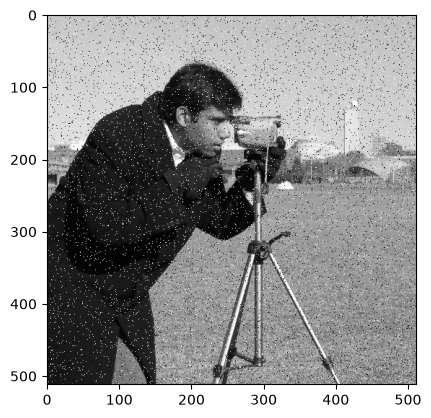

In [6]:
# adding salt and pepper noise
noise_sp = util.random_noise(img, mode='s&p', amount=0.05)
noise_sp = np.array(255 * noise_sp, dtype=np.uint8)
plt.imshow(noise_sp, cmap='gray')    

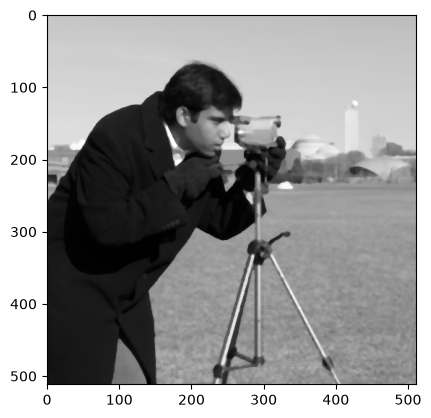

In [7]:
#Restore using Median Filter (Best for S&P)
restored_median = cv2.medianBlur(noise_sp, 5)
plt.imshow(restored_median, cmap='gray')

Minimize Gaussian Noise

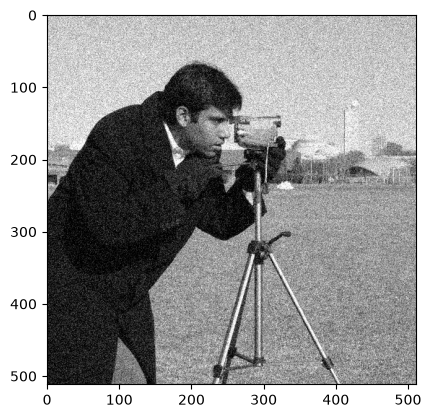

In [8]:
#Add Gaussian Noise
noise_gauss = util.random_noise(img, mode='gaussian', var=0.01)
noise_gauss = np.array(255 * noise_gauss, dtype=np.uint8)
plt.imshow(noise_gauss, cmap='gray')

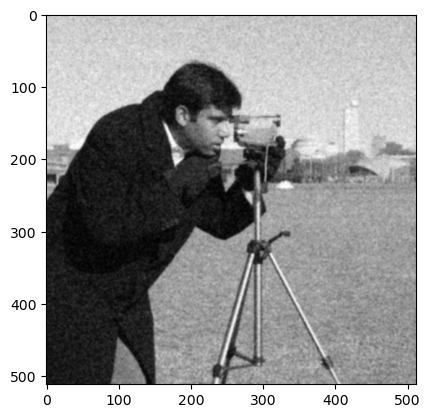

In [9]:
# Restore using Gaussian Blur (Low pass)
restored_gauss_blur = cv2.GaussianBlur(noise_gauss, (5, 5), 0)
plt.imshow(restored_gauss_blur, cmap='gray')

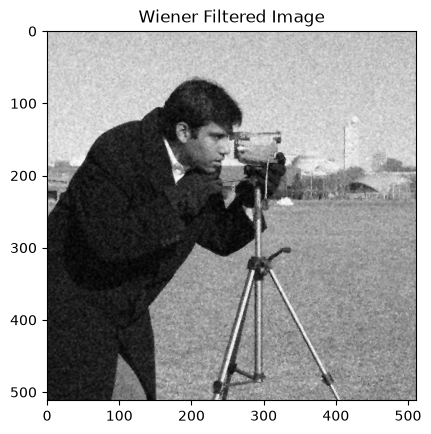

In [9]:
import numpy as np
from scipy.signal import wiener
import matplotlib.pyplot as plt

# Normalize and convert to float
noise_gauss = noise_gauss.astype(np.float32)
noise_gauss /= 255.0

# Apply Wiener filter with smaller window
restored_wiener = wiener(noise_gauss, 3)

# Display result
plt.imshow(restored_wiener, cmap='gray')
plt.title("Wiener Filtered Image")
plt.show()


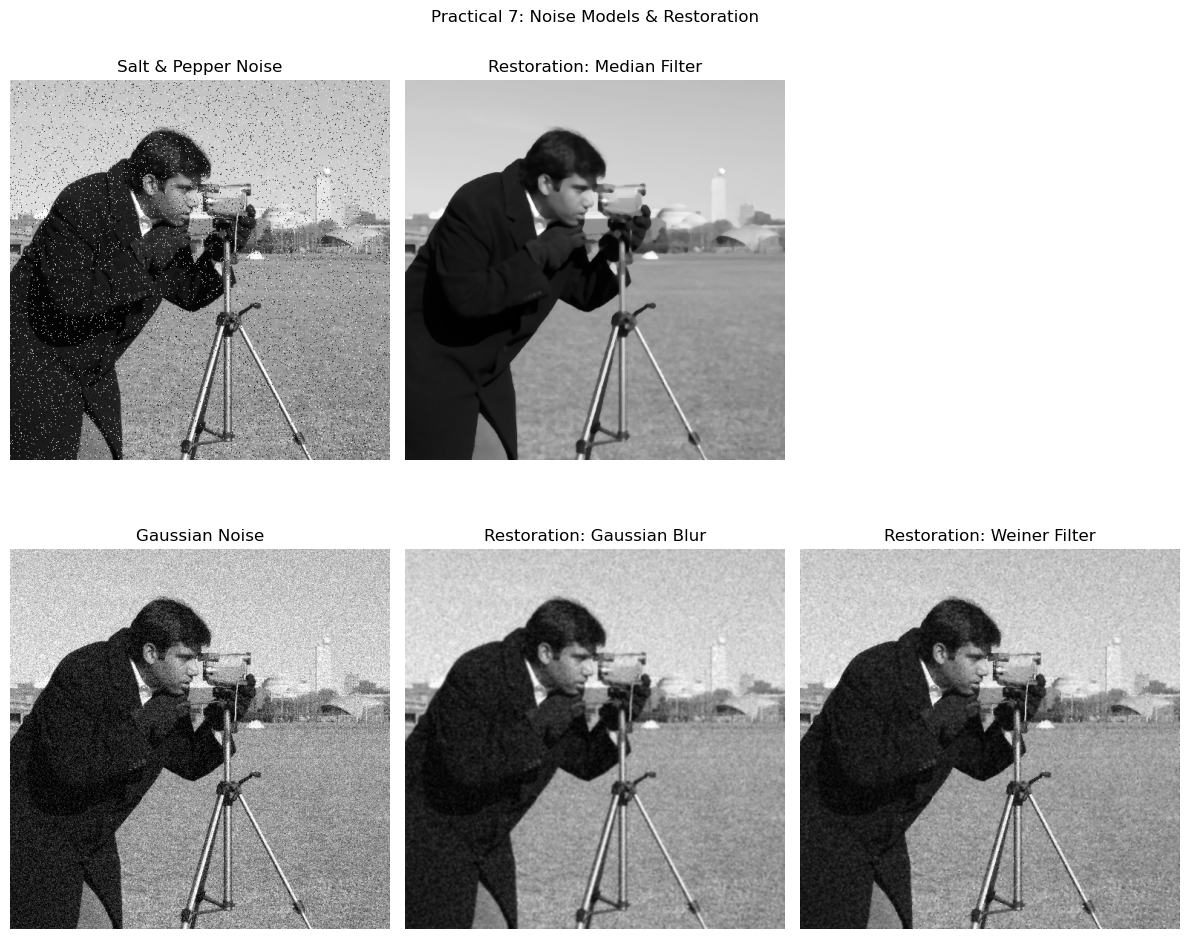

In [19]:
plt.figure(figsize=(12, 10))
    
plt.subplot(2, 3, 1)
plt.imshow(noise_sp, cmap='gray')
plt.title("Salt & Pepper Noise")
plt.axis('off')
    
plt.subplot(2, 3, 2)
plt.imshow(restored_median, cmap='gray')
plt.title("Restoration: Median Filter")
plt.axis('off')
    
plt.subplot(2, 3, 4)
plt.imshow(noise_gauss, cmap='gray')
plt.title("Gaussian Noise")
plt.axis('off')
    
plt.subplot(2, 3, 5)
plt.imshow(restored_gauss_blur, cmap='gray')
plt.title("Restoration: Gaussian Blur")
plt.axis('off')
    
plt.subplot(2, 3, 6)
plt.imshow(restored_wiener, cmap='gray')
plt.title("Restoration: Weiner Filter")
plt.axis('off')

plt.suptitle("Practical 7: Noise Models & Restoration")
plt.tight_layout()
plt.show()